# Batik Checker — Classical Machine Learning (Self-contained)

**Course:** Pengolahan Citra dan Visi Komputer  
**Task:** Classify Indonesian batik motifs from photos using classical machine learning (no deep learning).

This notebook is **self-contained**: all preprocessing, feature extraction, training, evaluation, and model-saving code lives in the cells below. Change the numbers and re-run the cells to **retrain**.

Flow: **preprocessing → features (GLCM + LBP + HSV histogram) → training (SVM & Random Forest) → evaluation → save model**.

## Table of contents
1. Imports & configuration
2. Dataset exploration
3. Preprocessing functions
4. Feature extraction functions (GLCM + LBP + HSV)
5. Build the dataset (X, y)
6. 80/20 split + scaling
7. Training: SVM & Random Forest
8. Evaluation (accuracy, classification report, confusion matrix)
9. Cross-validation for a more stable estimate
10. Comparison & saving the best model
11. Testing predictions on new images

## 1. Imports & Configuration

All **important parameters** are collected here so they are easy to tweak: image size, class list, GLCM/LBP/HSV parameters, and training settings.

In [1]:
import json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

%matplotlib inline
sns.set_theme(style="whitegrid")
print("cv2", cv2.__version__)

cv2 5.1.0


In [2]:
# ------------------------------------------------------------------
# CONFIGURATION — change these for experiments / retraining
# ------------------------------------------------------------------
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / "data" / "selected"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Classes used (folder names inside data/selected/)
CLASSES = ["parang", "kawung", "megamendung", "cendrawasih", "ceplok"]

# Preprocessing
IMG_SIZE = (128, 128)
GAUSSIAN_KERNEL = (5, 5)
GAUSSIAN_SIGMA = 0

# GLCM (texture)
GLCM_DISTANCES = [1, 2]
GLCM_ANGLES = [0, 45, 90, 135]   # degrees
GLCM_LEVELS = 32

# LBP (local texture)
LBP_RADIUS = 1
LBP_N_POINTS = 8
LBP_METHOD = "uniform"

# HSV colour histogram — use 4x4x4 (64 bins) to avoid a too-sparse vector;
# a large histogram (8x8x8) actually lowers SVM performance.
HSV_BINS = [4, 4, 4]
HSV_RANGES = [0, 180, 0, 256, 0, 256]

# Training
TEST_SIZE = 0.2
RANDOM_STATE = 42
N_SPLITS = 5

print("PROJECT_ROOT :", PROJECT_ROOT)
print("DATA_DIR     :", DATA_DIR)
print("CLASSES      :", CLASSES)

PROJECT_ROOT : C:\WiseBrilliance\PCVK\Final_Project
DATA_DIR     : C:\WiseBrilliance\PCVK\Final_Project\data\selected
CLASSES      : ['parang', 'kawung', 'megamendung', 'cendrawasih', 'ceplok']


## 2. Dataset Exploration

Dataset: **Indonesian Batik Motifs** (Kaggle, `dionisiusdh`). We use 5 classes whose motifs are clearly different from each other.

In [3]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def list_images(folder):
    return sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)

counts = {cls: len(list_images(DATA_DIR / cls)) for cls in CLASSES}
df_counts = pd.DataFrame({"class": list(counts), "image count": list(counts.values())})
display(df_counts)

,class,image count
0,parang,50
1,kawung,45
2,megamendung,47
3,cendrawasih,50
4,ceplok,48


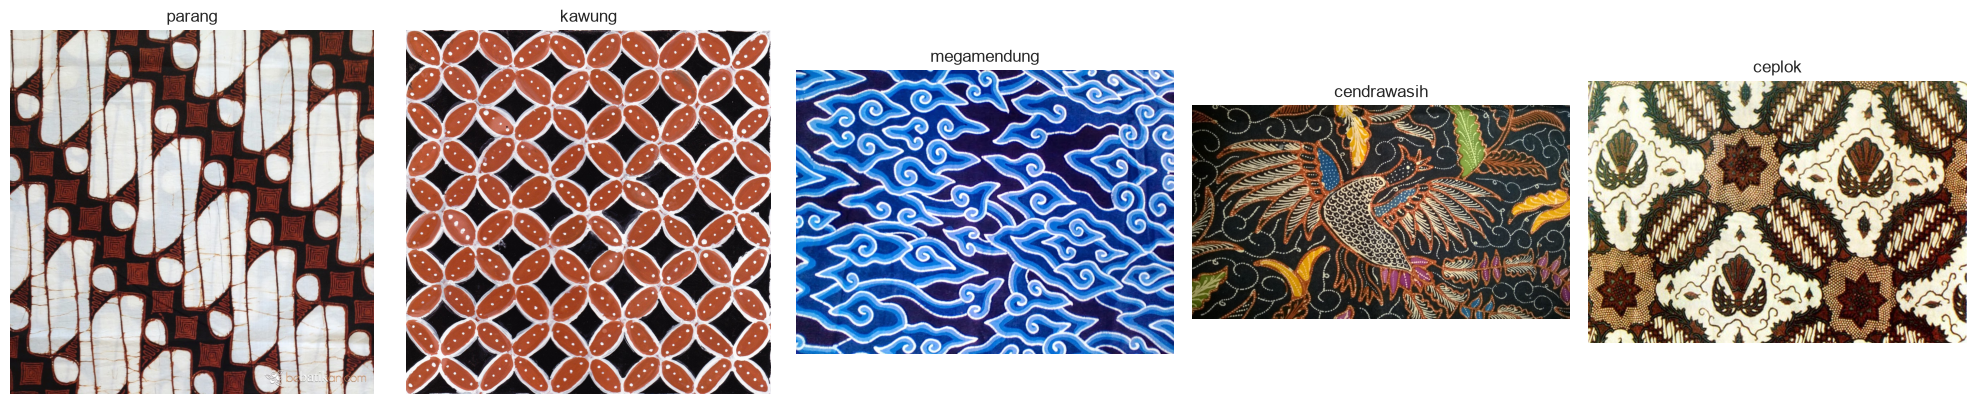

In [4]:
# Show one sample image per class
fig, axes = plt.subplots(1, len(CLASSES), figsize=(4 * len(CLASSES), 4))
for ax, cls in zip(axes, CLASSES):
    imgs = list_images(DATA_DIR / cls)
    if imgs:
        img = cv2.cvtColor(cv2.imread(str(imgs[0])), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
    ax.set_title(cls)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "dataset_samples.png", dpi=120)
plt.show()

## 3. Preprocessing Functions

As in the plan: **resize 128×128 → grayscale + HSV → Gaussian blur → histogram equalization**.

In [5]:
def load_image(path):
    """Read an image as BGR uint8."""
    img = cv2.imread(str(path))
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return img

def preprocess_image(img):
    """Full preprocessing pipeline. Returns a dict {gray, hsv, resized}."""
    # 1. Resize
    resized = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)
    # 2. Convert to grayscale and HSV
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(resized, cv2.COLOR_BGR2HSV)
    # 3. Gaussian blur to reduce noise
    gray = cv2.GaussianBlur(gray, GAUSSIAN_KERNEL, GAUSSIAN_SIGMA)
    # 4. Histogram equalization
    gray = cv2.equalizeHist(gray)
    return {"gray": gray, "hsv": hsv, "resized": resized}

def preprocess_from_path(path):
    return preprocess_image(load_image(path))

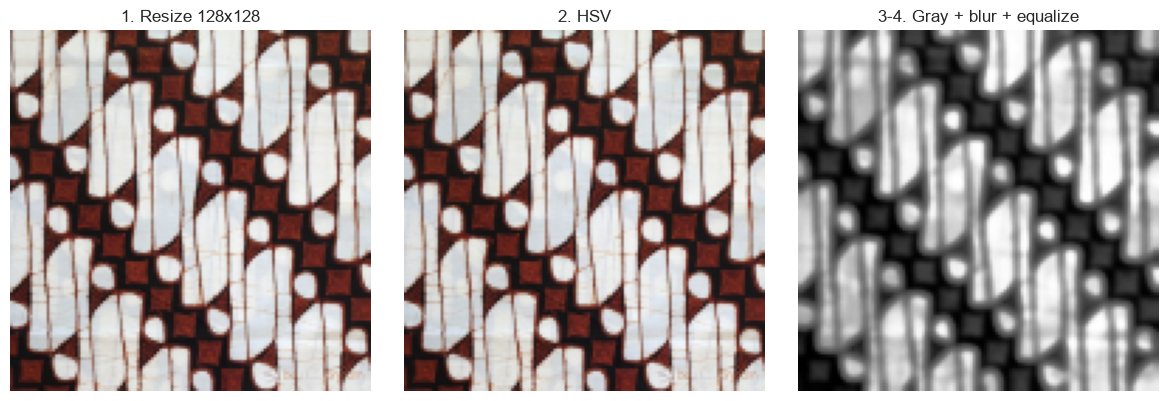

In [6]:
sample_path = list_images(DATA_DIR / "parang")[0]
raw = load_image(sample_path)
proc = preprocess_image(raw)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(cv2.cvtColor(proc["resized"], cv2.COLOR_BGR2RGB)); axes[0].set_title("1. Resize 128x128")
axes[1].imshow(cv2.cvtColor(proc["hsv"], cv2.COLOR_HSV2RGB)); axes[1].set_title("2. HSV")
axes[2].imshow(proc["gray"], cmap="gray"); axes[2].set_title("3-4. Gray + blur + equalize")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "preprocessing_steps.png", dpi=120)
plt.show()

## 4. Feature Extraction

Three feature blocks are concatenated into one vector:

- **GLCM** — texture (contrast, dissimilarity, homogeneity, energy, correlation).
- **LBP** — local texture (uniform-pattern histogram).
- **HSV histogram** — colour (4×4×4 = 64 bins).

Concatenation happens in `extract_features`. Scaling is done later with `StandardScaler` (fit on the training data only, to avoid leakage).

In [7]:
def glcm_features(gray):
    """Haralick texture features from the Gray-Level Co-occurrence Matrix."""
    quant = (gray.astype(np.float32) / 256.0 * GLCM_LEVELS).astype(np.uint8)
    quant = np.clip(quant, 0, GLCM_LEVELS - 1)
    angles = [np.deg2rad(a) for a in GLCM_ANGLES]
    glcm = graycomatrix(quant, distances=GLCM_DISTANCES, angles=angles,
                        levels=GLCM_LEVELS, symmetric=True, normed=True)
    props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]
    feats = []
    for prop in props:
        feats.extend(graycoprops(glcm, prop).flatten())
    return np.asarray(feats, dtype=np.float32)

def lbp_features(gray):
    """Normalised Local Binary Pattern histogram."""
    lbp = local_binary_pattern(gray, P=LBP_N_POINTS, R=LBP_RADIUS, method=LBP_METHOD)
    n_bins = LBP_N_POINTS + 2
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins))
    hist = hist.astype(np.float32)
    hist /= (hist.sum() + 1e-8)
    return hist

def hsv_histogram_features(hsv):
    """Normalised HSV colour histogram (4x4x4)."""
    hist = cv2.calcHist([hsv], [0, 1, 2], None, HSV_BINS, HSV_RANGES)
    hist = hist.flatten().astype(np.float32)
    hist /= (hist.sum() + 1e-8)
    return hist

def extract_features(gray, hsv):
    """Concatenate GLCM + LBP + HSV histogram into a single vector."""
    return np.concatenate([
        glcm_features(gray),
        lbp_features(gray),
        hsv_histogram_features(hsv),
    ]).astype(np.float32)

In [8]:
vec = extract_features(proc["gray"], proc["hsv"])
print("Feature vector length:", vec.shape[0])
print("  GLCM :", len(glcm_features(proc['gray'])), "features")
print("  LBP  :", len(lbp_features(proc['gray'])), "features")
print("  HSV  :", len(hsv_histogram_features(proc['hsv'])), "features")

Feature vector length: 114
  GLCM : 40 features
  LBP  : 10 features
  HSV  : 64 features


## 5. Build the Dataset (X, y)

Every image is processed and turned into a feature vector. Corrupted images are skipped automatically.

In [9]:
X, y = [], []
skipped = []

for label_idx, cls in enumerate(CLASSES):
    for img_path in list_images(DATA_DIR / cls):
        try:
            processed = preprocess_from_path(img_path)
        except FileNotFoundError:
            skipped.append(str(img_path))
            continue
        X.append(extract_features(processed["gray"], processed["hsv"]))
        y.append(label_idx)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y)
label_names = list(CLASSES)

if skipped:
    print(f"Skipped {len(skipped)} unreadable image(s): {skipped}")
print("X:", X.shape, "| y:", y.shape)
display(pd.Series(y).value_counts().sort_index().rename(index=dict(enumerate(CLASSES))).to_frame("count"))

Skipped 2 unreadable image(s): ['C:\\WiseBrilliance\\PCVK\\Final_Project\\data\\selected\\megamendung\\49.jpg', 'C:\\WiseBrilliance\\PCVK\\Final_Project\\data\\selected\\cendrawasih\\18.jpg']
X: (238, 114) | y: (238,)


,count
parang,50
kawung,45
megamendung,46
cendrawasih,49
ceplok,48


## 6. 80/20 Split + Scaling

A **stratified** split keeps each class proportion the same in train and test. `StandardScaler` is fit on the training data only.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)

Train: (190, 114) | Test: (48, 114)


## 7. Training: SVM & Random Forest

The SVM is wrapped in `CalibratedClassifierCV` so it can output confidence scores. Random Forest uses 300 trees. Change the hyperparameters in this cell and re-run to retrain.

In [11]:
svm = CalibratedClassifierCV(
    SVC(kernel="rbf", C=10, gamma="scale", random_state=RANDOM_STATE),
    ensemble=False,
)
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)

models = {"SVM": svm, "Random Forest": rf}
for name, clf in models.items():
    clf.fit(X_train_s, y_train)
    print(f"{name} trained.")

SVM trained.


Random Forest trained.


## 8. Evaluation

Accuracy, precision/recall/F1, and the confusion matrix for each model.

In [12]:
results = {}
for name, clf in models.items():
    y_pred = clf.predict(X_test_s)
    acc = accuracy_score(y_test, y_pred)
    results[name] = {
        "accuracy": acc,
        "report": classification_report(y_test, y_pred, target_names=label_names, zero_division=0),
        "cm": confusion_matrix(y_test, y_pred),
    }
    print(f"=== {name} === accuracy = {acc:.4f}")
    print(results[name]["report"])
    print()

=== SVM === accuracy = 0.5208
              precision    recall  f1-score   support

      parang       0.60      0.60      0.60        10
      kawung       0.43      0.33      0.38         9
 megamendung       0.73      0.89      0.80         9
 cendrawasih       0.50      0.50      0.50        10
      ceplok       0.30      0.30      0.30        10

    accuracy                           0.52        48
   macro avg       0.51      0.52      0.51        48
weighted avg       0.51      0.52      0.51        48


=== Random Forest === accuracy = 0.6875
              precision    recall  f1-score   support

      parang       0.78      0.70      0.74        10
      kawung       0.50      0.44      0.47         9
 megamendung       0.90      1.00      0.95         9
 cendrawasih       0.69      0.90      0.78        10
      ceplok       0.50      0.40      0.44        10

    accuracy                           0.69        48
   macro avg       0.67      0.69      0.68        48
weight

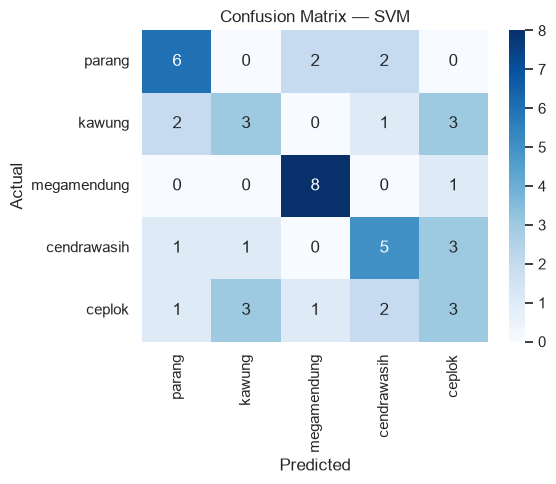

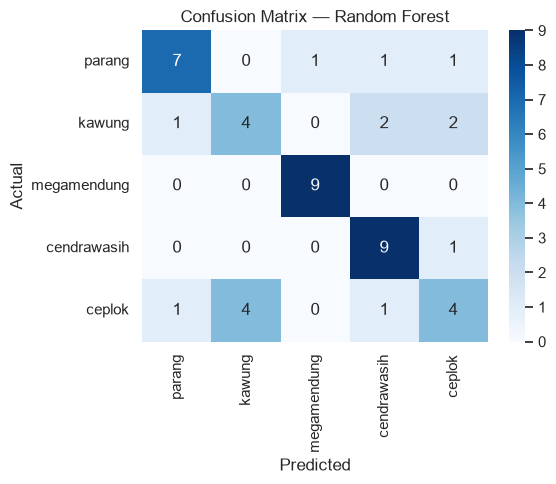

In [13]:
for name, res in results.items():
    plt.figure(figsize=(6, 5))
    sns.heatmap(res["cm"], annot=True, fmt="d", cmap="Blues",
                xticklabels=label_names, yticklabels=label_names)
    plt.title(f"Confusion Matrix — {name}")
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    plt.tight_layout()
    slug = name.lower().replace(" ", "_")
    plt.savefig(RESULTS_DIR / f"confusion_matrix_{slug}.png", dpi=120)
    plt.show()

## 9. Cross-Validation

Because the test set is only 48 images, a single split can be noisy. **5-fold stratified cross-validation** gives a more stable estimate.

SVM            5-fold accuracy = 0.5208 (+/- 0.0601)


Random Forest  5-fold accuracy = 0.6220 (+/- 0.0403)


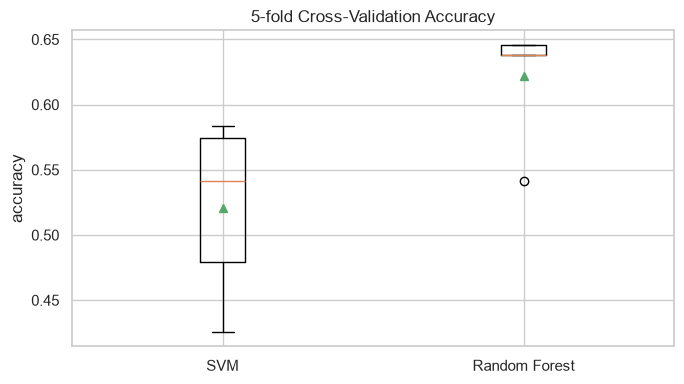

In [14]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_pipes = {
    "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", random_state=RANDOM_STATE)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)),
}

cv_scores = {}
for name, pipe in cv_pipes.items():
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
    cv_scores[name] = scores
    print(f"{name:14s} 5-fold accuracy = {scores.mean():.4f} (+/- {scores.std():.4f})")

plt.figure(figsize=(7, 4))
plt.boxplot([cv_scores[n] for n in cv_scores], tick_labels=list(cv_scores), showmeans=True)
plt.ylabel("accuracy")
plt.title("5-fold Cross-Validation Accuracy")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "cross_validation.png", dpi=120)
plt.show()

## 10. Comparison & Saving the Best Model

The model with the highest accuracy is saved together with the scaler and label list using `joblib`, so the web app (React frontend + FastAPI backend) can reuse them.

In [15]:
df_acc = pd.DataFrame({name: {"accuracy (holdout)": res["accuracy"], "accuracy (5-fold)": cv_scores[name].mean()}
                       for name, res in results.items()}).T
display(df_acc)

best_name = max(results, key=lambda k: results[k]["accuracy"])
best_model = models[best_name]
print(f"Best model: {best_name} (accuracy={results[best_name]['accuracy']:.4f})")

# Save the model, scaler, and labels
joblib.dump(best_model, MODELS_DIR / "best_model.joblib")
joblib.dump(scaler, MODELS_DIR / "scaler.joblib")
joblib.dump(label_names, MODELS_DIR / "labels.joblib")
print("Saved to:", MODELS_DIR)

# Save metrics
with open(RESULTS_DIR / "metrics.json", "w") as f:
    json.dump({
        "results": {n: {"accuracy_holdout": r["accuracy"],
                        "accuracy_cv_mean": float(cv_scores[n].mean()),
                        "accuracy_cv_std": float(cv_scores[n].std())}
                    for n, r in results.items()},
        "best_model": best_name,
        "classes": label_names,
        "feature_length": int(X.shape[1]),
    }, f, indent=2)
print("Metrics saved to:", RESULTS_DIR / "metrics.json")

,accuracy (holdout),accuracy (5-fold)
SVM,0.520833,0.520833
Random Forest,0.687500,0.621986


Best model: Random Forest (accuracy=0.6875)


Saved to: C:\WiseBrilliance\PCVK\Final_Project\models
Metrics saved to: C:\WiseBrilliance\PCVK\Final_Project\results\metrics.json


## 11. Testing Predictions on New Images

This function can be used to test any image. It is exactly the same flow used by the FastAPI backend.

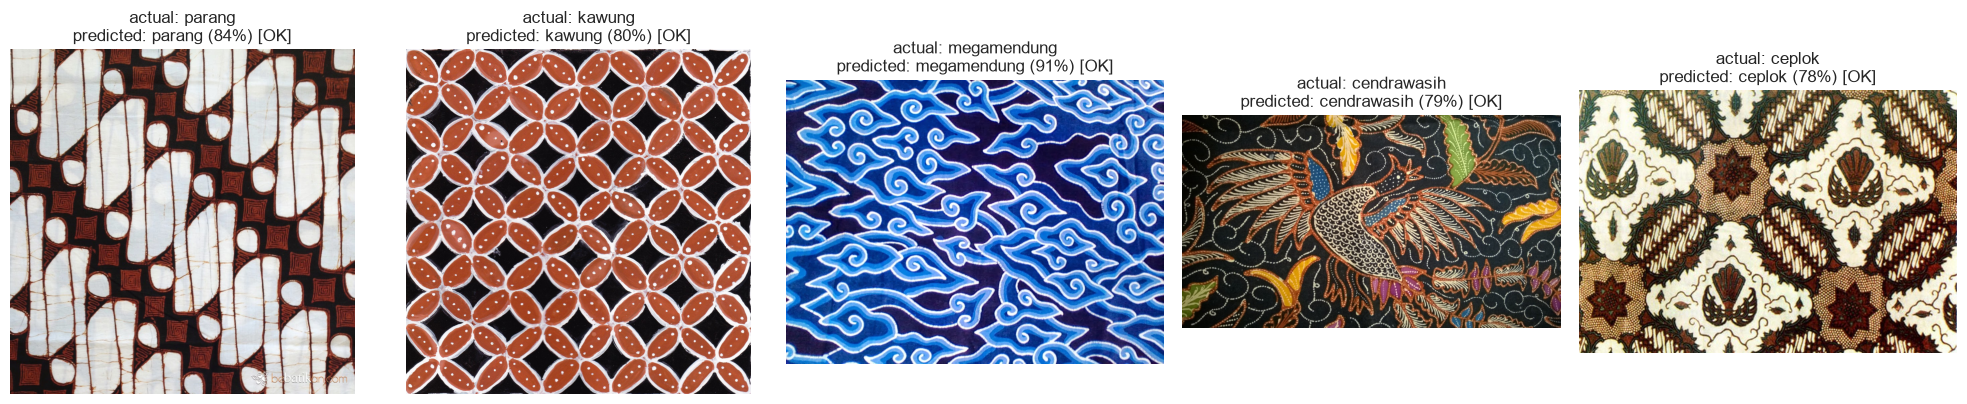

In [16]:
def predict_image(path, clf=best_model, sc=scaler, labels=label_names):
    """Predict a single image. Returns (label, confidence, probability_dict)."""
    processed = preprocess_from_path(path)
    vec = extract_features(processed["gray"], processed["hsv"])
    vec = sc.transform(vec.reshape(1, -1))
    probs = clf.predict_proba(vec)[0]
    idx = int(np.argmax(probs))
    return labels[idx], float(probs[idx]), {lab: float(p) for lab, p in zip(labels, probs)}

# Test 5 images (one per class)
fig, axes = plt.subplots(1, len(CLASSES), figsize=(4 * len(CLASSES), 4))
for ax, cls in zip(axes, CLASSES):
    p = list_images(DATA_DIR / cls)[0]
    label, conf, _ = predict_image(p)
    ax.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB))
    ok = "OK" if label == cls else "WRONG"
    ax.set_title(f"actual: {cls}\npredicted: {label} ({conf:.0%}) [{ok}]")
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "sample_predictions.png", dpi=120)
plt.show()

---
## Notes

- To **retrain**: change the parameters in the Configuration section (e.g. `IMG_SIZE`, `GLCM_LEVELS`, `HSV_BINS`, `TEST_SIZE`), or change the model hyperparameters in the Training section, then **Run All**.
- **Tesseract (OCR) is not used**: batik contains no text, so OCR is not relevant.
- The best model is automatically saved to the `models/` folder and used directly by the `backend/` FastAPI service.
- All result images (dataset samples, preprocessing steps, confusion matrices, cross-validation, sample predictions) are automatically saved to the `results/` folder for the report.